# Phase 1 · Notebook 01 — Project and Geographical Setup
**Dark Ecology Intelligence (DEI) · ANN PBL**

## Objective
1. Define three comparable **study windows** (Bengaluru, Mysuru, Nilgiri–Bandipur).
2. Build a common **5 km × 5 km grid** in one metric coordinate system.
3. **Check** the windows against real, published boundaries (OpenStreetMap) rather than just assuming what they contain.

## Background (beginner-friendly)
* A **study window** is the area we analyse. We need the three areas to be *comparable*, so each is the same size (50 km × 50 km).
* A **coordinate reference system (CRS)** says how coordinates map onto the Earth. Latitude/longitude degrees are not equal-length on the ground, so for metric work we use **UTM zone 43N (EPSG:32643)**, where units are metres. All three regions lie between 76° E and 78° E, inside UTM zone 43 (72° E – 78° E).
* A **grid** cuts each window into equal cells (5 km × 5 km = 25 km²). Later phases will summarise every dataset per cell, which gives the graph neural network one node per cell.

## Data sources used in this notebook
| Source | What we use | Licence |
|---|---|---|
| Our own geometric definitions | window centres, grid geometry (no observations) | – |
| OpenStreetMap via Nominatim API (https://nominatim.openstreetmap.org) | reference polygons (city limits, national parks) and landmark points, **only to check** the windows | ODbL 1.0 – “© OpenStreetMap contributors” |

> **Integrity note:** this notebook creates *geometry only*. It creates no observations or measurements.

## 1. Libraries and project paths
Required packages: `geopandas`, `shapely`, `pyproj`, `pandas`, `matplotlib`, `requests` (see `requirements.txt`).

In [1]:
# --- Locate the project root and make our utility modules importable ---
import sys
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".dei_project_root").exists():
    if root.parent == root:
        raise FileNotFoundError("Run this notebook from inside the dark_eco/ project folder.")
    root = root.parent
sys.path.insert(0, str(root / "scripts" / "utilities"))

import dei_paths as P
print("Project root:", P.ROOT)

Project root: /Users/apple/Documents/5th sem el/ANN_PBL/dark_eco


In [2]:
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape

import dei_geo as G
import dei_http as H

pd.set_option("display.max_colwidth", 80)
FIG_DIR = P.REPORTS / "phase_1" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("geopandas", gpd.__version__)

geopandas 1.2.0


## 2. The three provisional study windows
Each window is centred on an anchor point and is 50 km × 50 km. The anchors are a **design choice** (documented in `reports/phase_1/geographical_framework.md`), not a measured fact.

**Nilgiri–Bandipur is explicitly *not* the whole Nilgiri Biosphere Reserve.** It is a window around the Bandipur (Karnataka) – Mudumalai (Tamil Nadu) forest junction near the Moyar river.

In [3]:
regions = pd.DataFrame(G.REGIONS).T
regions.index.name = "region_id"
regions

,prefix,name,landscape_type,anchor,center_lat,center_lon
region_id,,,,,,
bengaluru,BLR,Bengaluru urban-peri-urban window,highly urbanised,Central Bengaluru (Vidhana Soudha area),12.9716,77.5946
mysuru,MYS,Mysuru peri-urban / transitional window,peri-urban and transitional,Mysuru city centre (Mysuru Palace area),12.3051,76.6551
nilgiri_bandipur,NB,Bandipur-Mudumalai forest window (Nilgiri-Bandipur),forest and protected-area,Karnataka-Tamil Nadu border near Moyar river (Bandipur/Mudumalai junction),11.66,76.6


## 3. Inspect previously saved boundary files before replacing them
An earlier draft of Phase 1 produced GeoJSON files using a hand-written UTM formula. Before replacing them, we load them and keep their coordinates so we can compare them with the new `pyproj`-based result. We are checking the old work, not taking it on trust.

In [4]:
old = {}
for rid in G.REGIONS:
    f = P.BOUNDARIES / f"{rid}_study_area.geojson"
    if f.exists():
        old[rid] = gpd.read_file(f)
        print(f"{f.name}: found, bounds = {tuple(round(v, 5) for v in old[rid].total_bounds)}")
    else:
        print(f"{f.name}: not found (first run)")

bengaluru_study_area.geojson: found, bounds = (np.float64(77.35773), np.float64(12.7396), np.float64(77.82295), np.float64(13.19586))
mysuru_study_area.geojson: found, bounds = (np.float64(76.42416), np.float64(12.07905), np.float64(76.88663), np.float64(12.5338))
nilgiri_bandipur_study_area.geojson: found, bounds = (np.float64(76.36582), np.float64(11.42861), np.float64(76.82697), np.float64(11.88316))


## 4. Build windows and grids with `pyproj`

In [5]:
windows = pd.concat([G.build_window(r) for r in G.REGIONS], ignore_index=True)
windows = gpd.GeoDataFrame(windows, crs=G.UTM_CRS)
grids = gpd.GeoDataFrame(pd.concat([G.build_grid(r) for r in G.REGIONS], ignore_index=True), crs=G.UTM_CRS)

# Lat/lon extents of each window (from the reprojected polygon)
w84 = windows.to_crs(G.WGS84_CRS)
b = w84.geometry.bounds
extent = pd.DataFrame({
    "region_id": windows.region_id,
    "lat_min": b.miny.round(4), "lat_max": b.maxy.round(4),
    "lon_min": b.minx.round(4), "lon_max": b.maxx.round(4),
    "utm_x_range_m": windows.utm_min_x.astype(int).astype(str) + " – " + windows.utm_max_x.astype(int).astype(str),
    "utm_y_range_m": windows.utm_min_y.astype(int).astype(str) + " – " + windows.utm_max_y.astype(int).astype(str),
    "area_km2": (windows.geometry.area / 1e6).round(2),
})
extent

,region_id,lat_min,lat_max,lon_min,lon_max,utm_x_range_m,utm_y_range_m,area_km2
0,bengaluru,12.7396,13.1959,77.3577,77.8229,756000 – 806000,1410000 – 1460000,2500.0
1,mysuru,12.0790,12.5338,76.4242,76.8866,655000 – 705000,1336000 – 1386000,2500.0
2,nilgiri_bandipur,11.4286,11.8832,76.3658,76.8270,649000 – 699000,1264000 – 1314000,2500.0


In [6]:
# Sanity checks on the grid
summary = grids.groupby("region_id").agg(n_cells=("cell_id", "count"),
                                          min_area_km2=("area_km2", "min"),
                                          max_area_km2=("area_km2", "max"),
                                          unique_ids=("cell_id", "nunique"))
assert (summary.n_cells == 100).all() and (summary.unique_ids == 100).all()
assert (summary.min_area_km2 == 25).all() and (summary.max_area_km2 == 25).all()
print("All grid checks passed: 3 regions x 100 cells, every cell exactly 25 km² in UTM 43N.")
summary

All grid checks passed: 3 regions x 100 cells, every cell exactly 25 km² in UTM 43N.


,n_cells,min_area_km2,max_area_km2,unique_ids
region_id,,,,
bengaluru,100,25.0,25.0,100
mysuru,100,25.0,25.0,100
nilgiri_bandipur,100,25.0,25.0,100


In [7]:
grids[["cell_id", "region_id", "row", "col", "centroid_lat", "centroid_lon", "area_km2"]].head(5)

,cell_id,region_id,row,col,centroid_lat,centroid_lon,area_km2
0,BLR_R01_C01,bengaluru,1,1,12.766487,77.380947,25.0
1,BLR_R01_C02,bengaluru,1,2,12.766068,77.426971,25.0
2,BLR_R01_C03,bengaluru,1,3,12.765641,77.472994,25.0
3,BLR_R01_C04,bengaluru,1,4,12.765206,77.519015,25.0
4,BLR_R01_C05,bengaluru,1,5,12.764763,77.565034,25.0


### 4.1 Compare with the earlier hand-written projection
If the old formula was right, the window corners should agree with `pyproj` to within a few centimetres.

In [8]:
rows = []
for rid, old_gdf in old.items():
    new_geom = w84.loc[w84.region_id == rid].to_crs(G.UTM_CRS).geometry.iloc[0]
    old_geom = old_gdf.to_crs(G.UTM_CRS).geometry.iloc[0]
    # Hausdorff distance = largest distance between the two outlines (metres)
    rows.append({"region_id": rid, "max_outline_difference_m": round(new_geom.hausdorff_distance(old_geom), 4)})
pd.DataFrame(rows) if rows else "No earlier files to compare."

,region_id,max_outline_difference_m
0,bengaluru,0.0
1,mysuru,0.0
2,nilgiri_bandipur,0.0


## 5. Save the boundary and grid files (GeoJSON, WGS 84)

In [9]:
P.BOUNDARIES.mkdir(exist_ok=True)
written = []
w84.to_file(P.BOUNDARIES / "study_areas_summary.geojson", driver="GeoJSON"); written.append("study_areas_summary.geojson")
for rid in G.REGIONS:
    w84[w84.region_id == rid].to_file(P.BOUNDARIES / f"{rid}_study_area.geojson", driver="GeoJSON")
    grids[grids.region_id == rid].to_crs(G.WGS84_CRS).to_file(P.BOUNDARIES / f"{rid}_5km_grid.geojson", driver="GeoJSON")
    written += [f"{rid}_study_area.geojson", f"{rid}_5km_grid.geojson"]
grids.to_crs(G.WGS84_CRS).to_file(P.BOUNDARIES / "all_regions_5km_grid.geojson", driver="GeoJSON"); written.append("all_regions_5km_grid.geojson")

pd.DataFrame([{"file": f, "size_kB": round((P.BOUNDARIES / f).stat().st_size / 1024, 1)} for f in written])

,file,size_kB
0,study_areas_summary.geojson,2.0
1,bengaluru_study_area.geojson,0.8
2,bengaluru_5km_grid.geojson,53.7
3,mysuru_study_area.geojson,0.8
4,mysuru_5km_grid.geojson,53.4
5,nilgiri_bandipur_study_area.geojson,0.8
6,nilgiri_bandipur_5km_grid.geojson,54.3
7,all_regions_5km_grid.geojson,161.0


## 6. Download OpenStreetMap reference features (to check the windows)
We use OSM to check what the windows actually contain. Features are requested **by fixed OSM ID**, so the result can be reproduced, through the Nominatim `/lookup` endpoint.

* We send one request (the Nominatim policy allows at most 1 request per second).
* **Checkpoint:** if the file already exists, it is reused and not downloaded again.
* The raw response is saved unchanged to `data/raw/osm_reference_boundaries/`, which Git ignores. Its metadata goes to `data/metadata/`.

OSM boundaries are community-mapped. They are good enough for a check, but they are **not** legally authoritative (for that, see WDPA / state gazettes, Notebook 02).

In [10]:
REF_FEATURES = {
    # osm id      : (label, kind, region it should help us check)
    "R7902476":  ("Bengaluru (OSM administrative boundary)", "polygon", "bengaluru"),
    "R8124064":  ("Bannerghatta National Park", "polygon", "bengaluru"),
    "W41662659": ("Hesaraghatta Lake", "polygon", "bengaluru"),
    "W252746837":("Kempegowda International Airport", "polygon", "bengaluru"),
    "R19125269": ("Mysuru (OSM local-authority boundary)", "polygon", "mysuru"),
    "R9329660":  ("Ranganathittu Bird Sanctuary", "polygon", "mysuru"),
    "R5867868":  ("Kabini Reservoir", "polygon", "mysuru"),
    "W159049291":("Bandipur National Park", "polygon", "nilgiri_bandipur"),
    "W159049306":("Mudumalai National Park", "polygon", "nilgiri_bandipur"),
    "N902588435":("Masinagudi (village)", "point", "nilgiri_bandipur"),
    "N245598696":("Gundlupet (town)", "point", "nilgiri_bandipur"),
    "N245592179":("Udhagamandalam / Ooty (town)", "point", "nilgiri_bandipur"),
}

raw_dir = P.RAW / "osm_reference_boundaries"
raw_dir.mkdir(parents=True, exist_ok=True)
raw_file = raw_dir / "nominatim_lookup_reference_features.json"
meta_file = P.METADATA / "osm_reference_boundaries_metadata.json"

if raw_file.exists():
    print("Checkpoint found - reusing", raw_file.name)
    payload = json.loads(raw_file.read_text())
else:
    resp = H.get("https://nominatim.openstreetmap.org/lookup",
                 params={"osm_ids": ",".join(REF_FEATURES), "format": "jsonv2", "polygon_geojson": 1},
                 pause=1.5)
    print("HTTP status:", resp.status_code)
    resp.raise_for_status()
    payload = resp.json()
    raw_file.write_text(json.dumps(payload))
    meta = {
        "dataset_name": "OpenStreetMap reference features (via Nominatim lookup)",
        "original_source": "OpenStreetMap contributors",
        "official_url": "https://www.openstreetmap.org",
        "api_endpoint": resp.url,
        "access_date_utc": H.utc_now(),
        "licence": "Open Database License (ODbL) 1.0 - attribution: © OpenStreetMap contributors",
        "geographical_coverage": "12 named features in/near the three DEI windows",
        "temporal_coverage": "Snapshot of OSM at access date",
        "file_format": "JSON (Nominatim jsonv2 with GeoJSON geometries)",
        "download_method": "HTTP GET, Nominatim /lookup by OSM ID",
        "original_filename": raw_file.name,
        "transformations": "none (stored as received)",
        "known_limitations": "Community-mapped; not legally authoritative; boundaries may differ from gazette notifications.",
        "used_by": "notebooks/phase_1_setup/01_project_and_geographical_setup.ipynb",
    }
    meta_file.write_text(json.dumps(meta, indent=2))

print("Features returned:", len(payload), "of", len(REF_FEATURES), "requested")
print("Raw file size:", round(raw_file.stat().st_size / 1024, 1), "kB")

Checkpoint found - reusing nominatim_lookup_reference_features.json
Features returned: 12 of 12 requested
Raw file size: 289.6 kB


In [11]:
recs = []
for item in payload:
    oid = item["osm_type"][0].upper() + str(item["osm_id"])
    label, kind, region = REF_FEATURES[oid]
    recs.append({"osm_id": oid, "label": label, "check_region": region,
                 "osm_category": f'{item["category"]}/{item["type"]}',
                 "geometry": shape(item["geojson"])})
ref = gpd.GeoDataFrame(recs, crs=G.WGS84_CRS)
missing = set(REF_FEATURES) - set(ref.osm_id)
print("Missing features:", missing or "none")
ref.drop(columns="geometry").assign(geom_type=ref.geom_type)

Missing features: none


,osm_id,label,check_region,osm_category,geom_type
0,R7902476,Bengaluru (OSM administrative boundary),bengaluru,boundary/administrative,Polygon
1,R8124064,Bannerghatta National Park,bengaluru,boundary/national_park,MultiPolygon
2,W41662659,Hesaraghatta Lake,bengaluru,water/reservoir,Polygon
3,W252746837,Kempegowda International Airport,bengaluru,aeroway/aerodrome,Polygon
4,R19125269,Mysuru (OSM local-authority boundary),mysuru,boundary/local_authority,Polygon
5,R9329660,Ranganathittu Bird Sanctuary,mysuru,leisure/nature_reserve,MultiPolygon
6,R5867868,Kabini Reservoir,mysuru,water/reservoir,Polygon
7,W159049291,Bandipur National Park,nilgiri_bandipur,boundary/national_park,Polygon
8,W159049306,Mudumalai National Park,nilgiri_bandipur,boundary/national_park,Polygon
9,N902588435,Masinagudi (village),nilgiri_bandipur,place/village,Point


## 7. How much of each reference feature lies inside its window?
We compute the area in UTM 43N and the share that falls inside the relevant window. For points, we report inside/outside. This checks claims such as “the window contains Bandipur National Park” against the data.

In [12]:
ref_utm = ref.to_crs(G.UTM_CRS)
win_by_region = windows.set_index("region_id").geometry
rows = []
for _, f in ref_utm.iterrows():
    w = win_by_region[f.check_region]
    if f.geometry.geom_type in ("Polygon", "MultiPolygon"):
        area = f.geometry.area / 1e6
        inside = f.geometry.intersection(w).area / 1e6
        rows.append({"feature": f.label, "window": f.check_region, "osm_area_km2": round(area, 1),
                     "area_inside_window_km2": round(inside, 1), "pct_inside": round(100 * inside / area, 1)})
    else:
        d = w.exterior.distance(f.geometry) / 1000
        rows.append({"feature": f.label, "window": f.check_region, "osm_area_km2": None,
                     "area_inside_window_km2": None,
                     "pct_inside": 100.0 if w.contains(f.geometry) else 0.0,
                     "note": ("inside" if w.contains(f.geometry) else "outside") + f", {d:.1f} km from window edge"})
coverage = pd.DataFrame(rows)
(P.METADATA / "phase_1_checks").mkdir(exist_ok=True)
coverage.to_csv(P.METADATA / "phase_1_checks" / "window_reference_feature_coverage.csv", index=False)
coverage

,feature,window,osm_area_km2,area_inside_window_km2,pct_inside,note
0,Bengaluru (OSM administrative boundary),bengaluru,717.2,717.2,100.0,NaN
1,Bannerghatta National Park,bengaluru,209.1,36.7,17.5,NaN
2,Hesaraghatta Lake,bengaluru,6.0,6.0,100.0,NaN
3,Kempegowda International Airport,bengaluru,16.1,3.6,22.6,NaN
4,Mysuru (OSM local-authority boundary),mysuru,86.3,86.3,100.0,NaN
5,Ranganathittu Bird Sanctuary,mysuru,1.9,1.9,100.0,NaN
6,Kabini Reservoir,mysuru,58.1,0.0,0.0,NaN
7,Bandipur National Park,nilgiri_bandipur,948.8,622.4,65.6,NaN
8,Mudumalai National Park,nilgiri_bandipur,336.0,335.6,99.9,NaN
9,Masinagudi (village),nilgiri_bandipur,NaN,NaN,100.0,"inside, 15.3 km from window edge"


### 7.1 Sensitivity check: would shifting the Nilgiri–Bandipur window cover more protected forest?
Only part of Bandipur NP falls inside the current window. Below we slide the 50 km window in 5 km steps, up to 20 km in each direction, and measure how much of the **combined Bandipur + Mudumalai** area (OSM polygons) it covers. This is a geometric test only. The final choice is a research decision for the team.

In [13]:
from shapely.geometry import box
from shapely.ops import unary_union
pa = unary_union(ref_utm[ref_utm.label.isin(["Bandipur National Park", "Mudumalai National Park"])].geometry)
ooty = ref_utm[ref_utm.label.str.startswith("Udhagamandalam")].geometry.iloc[0]
x0, y0, x1, y1 = windows.set_index("region_id").loc["nilgiri_bandipur", ["utm_min_x", "utm_min_y", "utm_max_x", "utm_max_y"]]
rows = []
for dx in range(-20_000, 20_001, 5_000):
    for dy in range(-20_000, 20_001, 5_000):
        wb = box(x0 + dx, y0 + dy, x1 + dx, y1 + dy)
        rows.append({"shift_east_km": dx / 1000, "shift_north_km": dy / 1000,
                     "pa_covered_km2": round(pa.intersection(wb).area / 1e6, 1),
                     "pct_of_PA_area": round(100 * pa.intersection(wb).area / pa.area, 1),
                     "pct_of_window_that_is_PA": round(100 * pa.intersection(wb).area / wb.area, 1),
                     "contains_ooty": wb.contains(ooty)})
shift = pd.DataFrame(rows)
print(f"Combined Bandipur + Mudumalai OSM area: {pa.area/1e6:.1f} km²")
print("Current window (0, 0):")
display(shift[(shift.shift_east_km == 0) & (shift.shift_north_km == 0)])
print("Top 5 shifts by protected-area coverage:")
shift.sort_values("pa_covered_km2", ascending=False).head(5)

Combined Bandipur + Mudumalai OSM area: 1284.8 km²


Current window (0, 0):


,shift_east_km,shift_north_km,pa_covered_km2,pct_of_PA_area,pct_of_window_that_is_PA,contains_ooty
40,0.0,0.0,958.0,74.6,38.3,False


Top 5 shifts by protected-area coverage:


,shift_east_km,shift_north_km,pa_covered_km2,pct_of_PA_area,pct_of_window_that_is_PA,contains_ooty
15,-15.0,10.0,1123.8,87.5,45.0,False
14,-15.0,5.0,1105.0,86.0,44.2,False
24,-10.0,10.0,1101.4,85.7,44.1,False
6,-20.0,10.0,1092.8,85.1,43.7,False
16,-15.0,15.0,1086.0,84.5,43.4,False


## 8. Maps of the three windows with the 5 km grid and OSM reference features

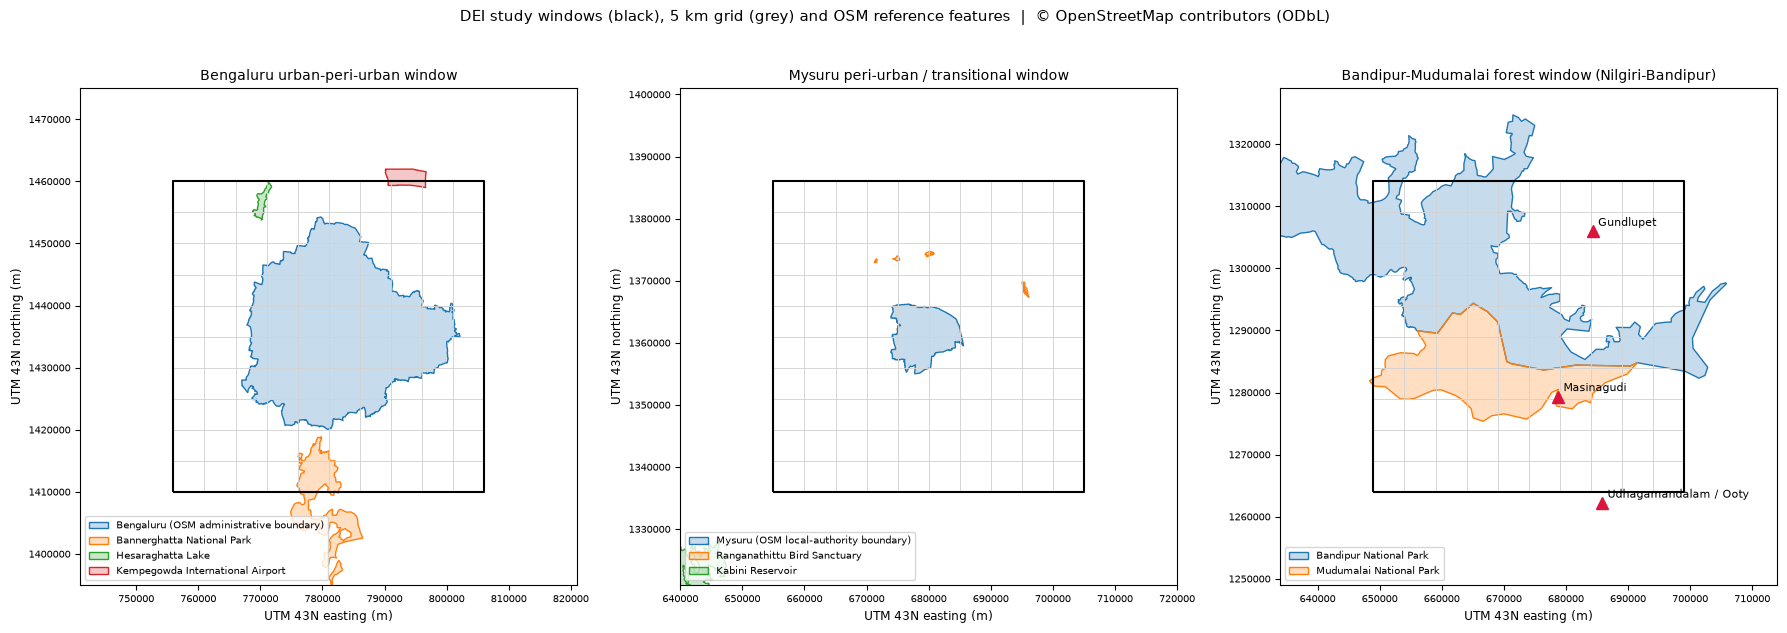

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, rid in zip(axes, G.REGIONS):
    g = grids[grids.region_id == rid]
    w = windows[windows.region_id == rid]
    r = ref_utm[ref_utm.check_region == rid]
    pad = 15_000
    minx, miny, maxx, maxy = w.total_bounds
    g.boundary.plot(ax=ax, color="lightgrey", linewidth=0.5)
    w.boundary.plot(ax=ax, color="black", linewidth=1.5)
    polys = r[r.geom_type.isin(["Polygon", "MultiPolygon"])]
    pts = r[r.geom_type == "Point"]
    colors = plt.cm.tab10.colors
    for k, (_, f) in enumerate(polys.iterrows()):
        gpd.GeoSeries([f.geometry], crs=G.UTM_CRS).plot(ax=ax, facecolor=(*colors[k % 10], 0.25),
                                                         edgecolor=colors[k % 10], linewidth=1, label=f.label)
    for k, (_, f) in enumerate(pts.iterrows()):
        ax.plot(f.geometry.x, f.geometry.y, marker="^", color="crimson", markersize=8)
        ax.annotate(f.label.split(" (")[0], (f.geometry.x, f.geometry.y), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlim(minx - pad, maxx + pad); ax.set_ylim(miny - pad, maxy + pad)
    ax.set_title(G.REGIONS[rid]["name"], fontsize=10)
    ax.set_xlabel("UTM 43N easting (m)"); ax.set_ylabel("UTM 43N northing (m)")
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=(*colors[k % 10], 0.25), edgecolor=colors[k % 10]) for k in range(len(polys))]
    ax.legend(handles, polys.label.tolist(), fontsize=7, loc="lower left")
    ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=7)
fig.suptitle("DEI study windows (black), 5 km grid (grey) and OSM reference features  |  © OpenStreetMap contributors (ODbL)", fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "study_windows_with_osm_reference.png", dpi=150)
plt.show()

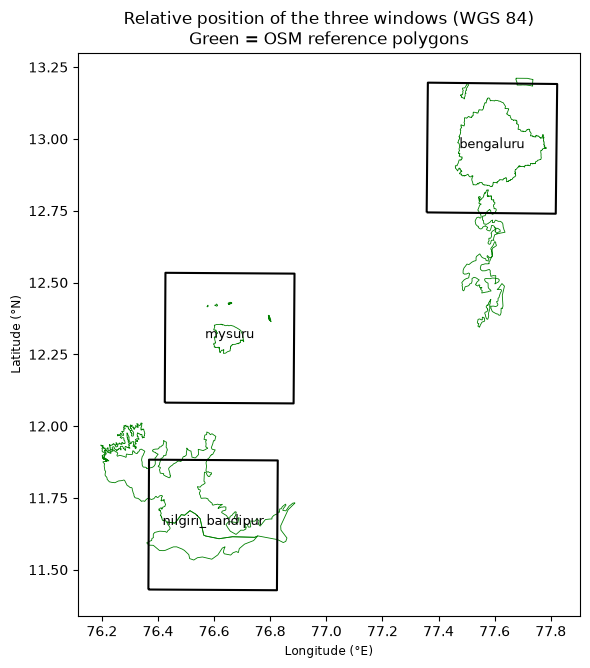

In [15]:
fig, ax = plt.subplots(figsize=(6, 7))
w84.boundary.plot(ax=ax, color="black")
for _, row in w84.iterrows():
    c = row.geometry.centroid
    ax.annotate(row.region_id, (c.x, c.y), ha="center", fontsize=9)
ref[ref.geom_type != "Point"].plot(ax=ax, facecolor="none", edgecolor="green", linewidth=0.6)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title("Relative position of the three windows (WGS 84)\nGreen = OSM reference polygons")
plt.tight_layout(); fig.savefig(FIG_DIR / "study_windows_overview.png", dpi=150); plt.show()

## 9. Interpretation of the checks
PENDING

## 10. Grid design: advantages, limitations and edge cases
**Advantages**
* All 300 cells are exactly 25 km² in UTM 43N, so cells can be compared directly across regions.
* A regular 10 × 10 lattice gives a simple, identical graph structure (rook or queen adjacency) for spatio-temporal GNNs.
* 5 km is coarser than every planned raster (10 m – 1 km), except ERA5-Land (~9 km), so most rasters can be aggregated *up* to the grid without inventing detail.

**Limitations**
* **ERA5-Land (0.1°, about 11 km)** is coarser than a cell. Neighbouring cells will share climate values, which must not be read as independent information.
* A 5 km cell mixes habitats (for example a forest edge and a village). Fine-scale light effects on species are averaged away.
* The windows are **rectangles, not ecological or administrative units**. Section 9 shows exactly what they include and exclude.
* Biodiversity records with coordinate uncertainty above about 2.5 km cannot be placed in a cell reliably. They will be filtered in Phase 3.

**Planned handling (to be done in later phases with real data, not here)**
* *Water bodies:* the fraction of each cell that is water will come from ESA WorldCover class 80 (Phase 5). Cells will be kept, with water fraction as a covariate.
* *Missing coverage (e.g. cloudy monsoon months in VIIRS):* missing values stay **missing** and are flagged using the products' own cloud-free-coverage layers. They will not be filled with invented values.
* *Boundary clipping:* cells are not clipped to administrative lines. Rasters are summarised over the full cell, and the fraction of each cell inside protected areas or city limits is recorded as an attribute.

## 11. Limitations of this notebook
PENDING

## 12. Summary and next steps
PENDING